In [2]:

# ==========================================
# 01. ENVIRONMENT CHECK
# Kiểm tra môi trường thực nghiệm
# ==========================================

import sys
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import shap

print("=" * 50)
print("ENERGY FORECASTING - XAI RESEARCH")
print("=" * 50)

print("Python:", sys.version)
print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nEnvironment check completed!")


ENERGY FORECASTING - XAI RESEARCH
Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Python path: C:\Users\admin\Energy_Forecasting_XAI\.venv\Scripts\python.exe
Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1
XGBoost: 3.4.1
SHAP: 0.54.1

Current working directory:
C:\Users\admin\Energy_Forecasting_XAI\notebooks

Environment check completed!


In [3]:

# ==========================================
# 02. DATA DIRECTORY CHECK
# Kiểm tra dữ liệu đầu vào
# ==========================================

import os

data_path = "../data/raw"

print("Checking raw data directory...")

if os.path.exists(data_path):
    files = os.listdir(data_path)

    if len(files) == 0:
        print("Chua co file du lieu!")
    else:
        print("Danh sach file du lieu:")
        for file in files:
            print("-", file)
else:
    print("Thu muc data/raw chua ton tai!")


Checking raw data directory...
Chua co file du lieu!


In [4]:

import os
import pandas as pd

data_path = "../data/raw"

# Liệt kê các file dữ liệu
files = os.listdir(data_path)

print("CÁC FILE DỮ LIỆU:")
for file in files:
    print("-", file)

# Kiểm tra các sheet trong file Excel
for file in files:
    if file.endswith((".xlsx", ".xls")):
        print(f"\nFile: {file}")

        excel = pd.ExcelFile(
            os.path.join(data_path, file)
        )

        print("Các sheet:", excel.sheet_names)


CÁC FILE DỮ LIỆU:
- dataset.xlsx
- dataused.xlsx

File: dataset.xlsx
Các sheet: ['crude oil', 'Natural gas', 'coal', 'Treasury bill rate ', 'Long-term yield ', 'inflation', 'Stock return variance ', 'Growth crude oil production', 'Growth of Import Price Index ', 'Money supply', 'Industrial Production Index', 'Unemployment rate', 'energy expend per houshold(scor', 'TempAno', 'CO2 emission per cap', 'patents RE', 'LCOE', 'Annual change wind energy gener', 'Annual change of solar energy g', 'Annual change of hydropower Ene', 'Geopolitical Risk', 'Economic policy uncertainly']

File: dataused.xlsx
Các sheet: ['Sheet1']


In [5]:

import pandas as pd
import os

file_path = "../data/raw/dataset.xlsx"

excel = pd.ExcelFile(file_path)

# Kiểm tra từng sheet
for sheet in excel.sheet_names:

    df = pd.read_excel(file_path, sheet_name=sheet)

    print("\n" + "=" * 70)
    print("SHEET:", sheet)
    print("=" * 70)

    print("Kích thước:", df.shape)
    print("Tên các cột:", df.columns.tolist())

    print("\n5 dòng đầu tiên:")
    display(df.head())

    print("\nKiểu dữ liệu:")
    print(df.dtypes)

    print("\nSố lượng giá trị thiếu:")
    print(df.isnull().sum())



SHEET: crude oil
Kích thước: (9798, 2)
Tên các cột: ['date', 'wti']

5 dòng đầu tiên:


,date,wti
0,1986-01-02,25.56
1,1986-01-03,26.00
2,1986-01-06,26.53
3,1986-01-07,25.85
4,1986-01-08,25.87



Kiểu dữ liệu:
date    datetime64[us]
wti            float64
dtype: object

Số lượng giá trị thiếu:
date      0
wti     336
dtype: int64

SHEET: Natural gas
Kích thước: (6676, 2)
Tên các cột: ['date', 'GP']

5 dòng đầu tiên:


,date,GP
0,1997-01-07,3.82
1,1997-01-08,3.80
2,1997-01-09,3.61
3,1997-01-10,3.92
4,1997-01-13,4.00



Kiểu dữ liệu:
date    datetime64[us]
GP             float64
dtype: object

Số lượng giá trị thiếu:
date    0
GP      1
dtype: int64

SHEET: coal
Kích thước: (4292, 2)
Tên các cột: ['date', 'coal']

5 dòng đầu tiên:


,date,coal
0,2006-10-16,49.049999
1,2006-10-17,49.250000
2,2006-10-18,49.400002
3,2006-10-19,48.750000
4,2006-10-20,49.000000


... (35 outputs left out)

,date,GR
0,1970-12-31,71.432656
1,1971-12-31,71.939535
2,1972-12-31,74.189709
3,1973-12-31,80.067077
4,1974-12-31,86.863291



Kiểu dữ liệu:
date    datetime64[us]
GR             float64
dtype: object

Số lượng giá trị thiếu:
date    0
GR      0
dtype: int64

SHEET: Economic policy uncertainly
Kích thước: (14105, 2)
Tên các cột: ['date', 'EPI']

5 dòng đầu tiên:


,date,EPI
0,1985-01-01,103.83
1,1985-01-02,296.43
2,1985-01-03,56.06
3,1985-01-04,118.45
4,1985-01-05,88.56



Kiểu dữ liệu:
date    datetime64[us]
EPI            float64
dtype: object

Số lượng giá trị thiếu:
date    0
EPI     0
dtype: int64


In [6]:

file_path = "../data/raw/dataused.xlsx"

df_used = pd.read_excel(file_path)

print("KÍCH THƯỚC DATAUSED:", df_used.shape)

print("\nTÊN CÁC CỘT:")
print(df_used.columns.tolist())

print("\n5 DÒNG ĐẦU:")
display(df_used.head())

print("\n5 DÒNG CUỐI:")
display(df_used.tail())

print("\nTHÔNG TIN DỮ LIỆU:")
df_used.info()

print("\nTHỐNG KÊ MÔ TẢ:")
display(df_used.describe(include="all"))


KÍCH THƯỚC DATAUSED: (4279, 39)

TÊN CÁC CỘT:
['coal', 'wti', 'GP', 'solarthermal', 'solarpvthermalhybrid', 'solarpv', 'wind', 'hydropower', 'marineandtidal', 'bioenergy', 'geothermal', 'bioenergyLCOE', 'geothermalLCOE', 'offshorewindLCOE', 'solarphotovoltaicLCOE', 'concentratedsolarLCOE', 'hydropowerLCOE', 'onshorewindLCOE', 'AC_HYD_E', 'AC_SOLAR_E', 'AC_WIND_E', 'GR', 'EPI', 'TEMP', 'EEPH', 'co2_per_capita', 'TB', 'LTY', 'I', 'SRV', 'GOP', 'GIPIO', 'M2', 'IPI', 'UMP', 'coal1', 'coal2', 'coal3', 'coal4']

5 DÒNG ĐẦU:


,coal,wti,GP,solarthermal,solarpvthermalhybrid,solarpv,wind,hydropower,marineandtidal,bioenergy,...,SRV,GOP,GIPIO,M2,IPI,UMP,coal1,coal2,coal3,coal4
0,0.027587,0.533491,0.292055,0.337095,0.245515,0.13928,0.258824,0.329919,0.408127,0.470195,...,0.000672,0.280304,0.584249,0.421879,0.555658,0.079129,0.027587,0.030084,0.029584,0.026339
1,0.030833,0.536124,0.269862,0.337095,0.245515,0.13928,0.258824,0.329919,0.408127,0.470195,...,0.000672,0.280304,0.584249,0.421879,0.555658,0.079129,0.027587,0.027587,0.030084,0.029584
2,0.032331,0.523287,0.251221,0.337095,0.245515,0.13928,0.258824,0.329919,0.408127,0.470195,...,0.000672,0.280304,0.584249,0.421879,0.555658,0.079129,0.030833,0.027587,0.027587,0.030084
3,0.027587,0.524988,0.235686,0.337095,0.245515,0.13928,0.258824,0.329919,0.408127,0.470195,...,0.000672,0.280304,0.584249,0.421879,0.555658,0.079129,0.032331,0.030833,0.027587,0.027587
4,0.027587,0.524549,0.258322,0.337095,0.245515,0.13928,0.258824,0.329919,0.408127,0.470195,...,0.000672,0.280304,0.584249,0.421879,0.555658,0.079129,0.027587,0.032331,0.030833,0.027587



5 DÒNG CUỐI:


,coal,wti,GP,solarthermal,solarpvthermalhybrid,solarpv,wind,hydropower,marineandtidal,bioenergy,...,SRV,GOP,GIPIO,M2,IPI,UMP,coal1,coal2,coal3,coal4
4274,0.176008,0.618465,0.052818,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.003087,0.482959,0.615586,0.406757,0.593873,0.072552,0.163650,0.164024,0.162776,0.163775
4275,0.173636,0.616490,0.052375,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.000340,0.482959,0.615586,0.406757,0.593873,0.072552,0.176008,0.163650,0.164024,0.162776
4276,0.178005,0.617862,0.056813,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.002821,0.482959,0.615586,0.406757,0.593873,0.072552,0.173636,0.176008,0.163650,0.164024
4277,0.179878,0.625597,0.056813,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.000006,0.482959,0.615586,0.406757,0.593873,0.072552,0.178005,0.173636,0.176008,0.163650
4278,0.181251,0.635197,0.059920,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.000995,0.482959,0.615586,0.406757,0.593873,0.072552,0.179878,0.178005,0.173636,0.176008



THÔNG TIN DỮ LIỆU:
<class 'pandas.DataFrame'>
RangeIndex: 4279 entries, 0 to 4278
Data columns (total 39 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   coal                   4279 non-null   float64
 1   wti                    4279 non-null   float64
 2   GP                     4279 non-null   float64
 3   solarthermal           4279 non-null   float64
 4   solarpvthermalhybrid   4279 non-null   float64
 5   solarpv                4279 non-null   float64
 6   wind                   4279 non-null   float64
 7   hydropower             4279 non-null   float64
 8   marineandtidal         4279 non-null   float64
 9   bioenergy              4279 non-null   float64
 10  geothermal             4279 non-null   float64
 11  bioenergyLCOE          4279 non-null   float64
 12  geothermalLCOE         4279 non-null   float64
 13  offshorewindLCOE       4279 non-null   float64
 14  solarphotovoltaicLCOE  4279 non-null   float64


,coal,wti,GP,solarthermal,solarpvthermalhybrid,solarpv,wind,hydropower,marineandtidal,bioenergy,...,SRV,GOP,GIPIO,M2,IPI,UMP,coal1,coal2,coal3,coal4
count,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,...,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000,4279.000000
mean,0.145896,0.601001,0.120620,0.719466,0.572617,0.626013,0.727956,0.774298,0.783173,0.767172,...,0.004808,0.482959,0.615586,0.406757,0.593873,0.072552,0.145860,0.145825,0.145790,0.145756
std,0.149475,0.124074,0.088840,0.230661,0.229425,0.252157,0.243604,0.244255,0.243064,0.255919,...,0.025203,0.241638,0.127037,0.095927,0.081790,0.070157,0.149485,0.149495,0.149505,0.149515
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.056984,0.497778,0.063027,0.711967,0.463722,0.626013,0.716109,0.774298,0.759128,0.741409,...,0.000672,0.336669,0.571411,0.380440,0.570071,0.059508,0.056922,0.056922,0.056922,0.056922
50%,0.109474,0.598607,0.096760,0.735099,0.572617,0.668417,0.767474,0.858001,0.848645,0.834323,...,0.000672,0.474895,0.626662,0.406757,0.593873,0.070101,0.109474,0.109474,0.109474,0.109350
75%,0.158220,0.704509,0.142921,0.841433,0.680589,0.744115,0.863899,0.915931,0.965842,0.946648,...,0.002328,0.602916,0.679542,0.409286,0.620164,0.076781,0.157970,0.157658,0.157533,0.157471
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# Đọc dữ liệu
df_uni = pd.read_csv("../data/raw/dataset_uni.csv")
df_multi = pd.read_csv("../data/raw/dataset_multi.csv")

# Chuyển Date sang kiểu ngày tháng
df_uni["Date"] = pd.to_datetime(df_uni["Date"])
df_multi["Date"] = pd.to_datetime(df_multi["Date"])

# Sắp xếp theo thời gian
df_uni = df_uni.sort_values("Date").reset_index(drop=True)
df_multi = df_multi.sort_values("Date").reset_index(drop=True)

print("Univariate:", df_uni.shape)
print("Multivariate:", df_multi.shape)

Univariate: (4215, 2)
Multivariate: (4215, 8)


In [10]:
print("UNIVARIATE")
display(df_uni.head())
display(df_uni.info())

print("MULTIVARIATE")
display(df_multi.head())
display(df_multi.info())

print("Missing values:")
display(df_multi.isnull().sum())

UNIVARIATE


,Date,wti
0,2006-10-16,59.91
1,2006-10-17,58.91
2,2006-10-18,57.66
3,2006-10-19,58.55
4,2006-10-20,57.35


<class 'pandas.DataFrame'>
RangeIndex: 4215 entries, 0 to 4214
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4215 non-null   datetime64[us]
 1   wti     4215 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 66.0 KB


None

MULTIVARIATE


,Date,wti,GP,coal,TB,LTY,EPI,SRV
0,2006-10-16,59.91,5.13,49.049999,4.96,4.6,42.85,0.000002
1,2006-10-17,58.91,6.26,49.250000,4.96,4.6,143.06,0.000002
2,2006-10-18,57.66,6.07,49.400002,4.96,4.6,28.55,0.000002
3,2006-10-19,58.55,6.77,48.750000,4.97,4.6,20.71,0.000002
4,2006-10-20,57.35,6.88,49.000000,4.96,4.6,88.78,0.000002


<class 'pandas.DataFrame'>
RangeIndex: 4215 entries, 0 to 4214
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4215 non-null   datetime64[us]
 1   wti     4215 non-null   float64       
 2   GP      4211 non-null   float64       
 3   coal    4175 non-null   float64       
 4   TB      4215 non-null   float64       
 5   LTY     4200 non-null   float64       
 6   EPI     4215 non-null   float64       
 7   SRV     4215 non-null   float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 263.6 KB


None

Missing values:


Date     0
wti      0
GP       4
coal    40
TB       0
LTY     15
EPI      0
SRV      0
dtype: int64

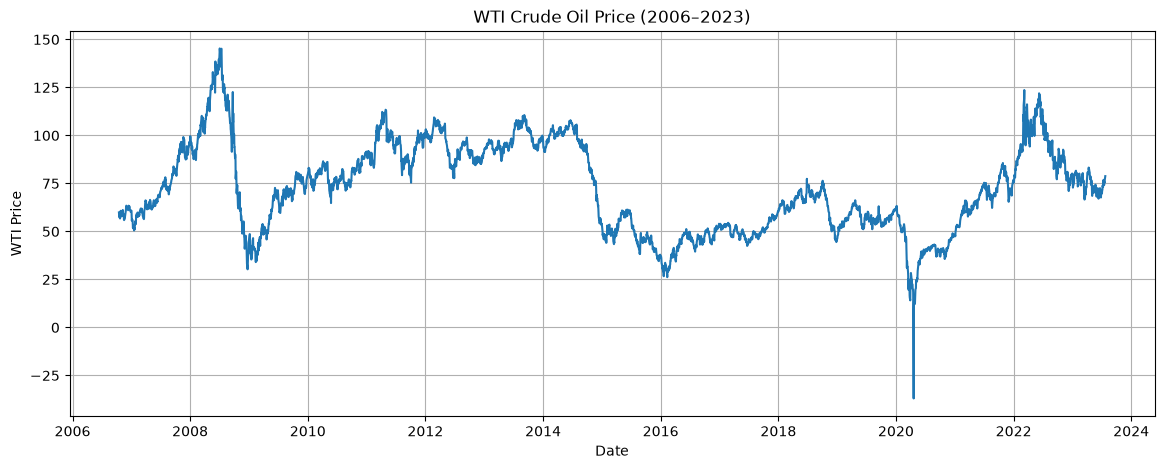

In [11]:
plt.figure(figsize=(14, 5))

plt.plot(df_uni["Date"], df_uni["wti"])

plt.title("WTI Crude Oil Price (2006–2023)")
plt.xlabel("Date")
plt.ylabel("WTI Price")
plt.grid(True)

plt.show()

In [12]:
# Các biến cần kiểm tra
missing_cols = ["GP", "coal", "LTY"]

for col in missing_cols:
    missing = df_multi[col].isnull()

    # Nhóm các đoạn liên tiếp có cùng trạng thái thiếu/không thiếu
    groups = missing.ne(missing.shift()).cumsum()

    missing_periods = (
        df_multi[missing]
        .groupby(groups[missing])
        .agg(
            start_date=("Date", "min"),
            end_date=("Date", "max"),
            missing_count=("Date", "count")
        )
    )

    print(f"\nCác đoạn thiếu của {col}:")
    display(missing_periods)


Các đoạn thiếu của GP:


,start_date,end_date,missing_count
GP,,,
2,2018-01-05,2018-01-05,1
4,2020-07-02,2020-07-02,1
6,2020-12-31,2020-12-31,1
8,2022-10-10,2022-10-10,1



Các đoạn thiếu của coal:


,start_date,end_date,missing_count
coal,,,
2,2008-03-24,2008-03-24,1
4,2008-05-05,2008-05-05,1
6,2008-05-27,2008-05-27,1
8,2008-06-17,2008-06-17,1
10,2008-07-23,2008-07-24,2
12,2008-08-25,2008-08-26,2
14,2009-04-28,2009-04-28,1
16,2010-05-17,2010-05-20,4
18,2010-05-26,2010-05-26,1



Các đoạn thiếu của LTY:


,start_date,end_date,missing_count
LTY,,,
2,2023-07-03,2023-07-24,15


In [13]:
# Tạo dataset Multivariate chính thức
df_multi_model = df_multi[
    ["Date", "wti", "GP", "coal", "TB", "EPI", "SRV"]
].copy()

# Kiểm tra kích thước
print("Kích thước:", df_multi_model.shape)

# Kiểm tra giá trị thiếu
print(df_multi_model.isnull().sum())

# Xem 5 dòng đầu và cuối
display(df_multi_model.head())
display(df_multi_model.tail())

Kích thước: (4215, 7)
Date     0
wti      0
GP       4
coal    40
TB       0
EPI      0
SRV      0
dtype: int64


,Date,wti,GP,coal,TB,EPI,SRV
0,2006-10-16,59.91,5.13,49.049999,4.96,42.85,0.000002
1,2006-10-17,58.91,6.26,49.250000,4.96,143.06,0.000002
2,2006-10-18,57.66,6.07,49.400002,4.96,28.55,0.000002
3,2006-10-19,58.55,6.77,48.750000,4.97,20.71,0.000002
4,2006-10-20,57.35,6.88,49.000000,4.96,88.78,0.000002


,Date,wti,GP,coal,TB,EPI,SRV
4210,2023-07-18,75.76,2.52,108.949997,5.25,104.31,9.486715e-06
4211,2023-07-19,75.40,2.51,108.000000,5.26,30.42,1.046119e-06
4212,2023-07-20,75.65,2.61,109.750000,5.26,258.12,8.669682e-06
4213,2023-07-21,77.06,2.61,110.500000,5.27,81.16,1.981221e-08
4214,2023-07-24,78.81,2.68,111.050003,5.28,106.15,3.057106e-06
